# Бонус: Visualization — RoI-ембедінги Faster R-CNN (T0)
Для кожного GT-об'єкта з val береться його ознаковий вектор з другої стадії Faster R-CNN (RoIAlign → box head, 1024-d),
тобто те, що бачить класифікатор, коли вирішує, що це за об'єкт. Вектори проєктуються в 2D (PCA → t-SNE) і розфарбовуються
за класом, розміром і результатом детекції (знайдено / не той клас / пропущено).
Input: дані змагання + Output ноутбука 04 (`T0_frcnn_1024/weights.pt`). GPU: одна T4 або P100.

## 1. Модель T0 і дані

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("pycocotools") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pycocotools"])

import contextlib, io, os
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from pycocotools.coco import COCO
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou

NAMES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEED, N_FRAMES, MAX_POINTS = 0, 300, 6000
DEV = torch.device("cuda")
torch.manual_seed(SEED); np.random.seed(SEED)
ROOT = next(p.parent.parent for p in Path("/kaggle/input").rglob("val/annotations_coco.json"))
W_PATH = next(p for p in Path("/kaggle/input").rglob("weights.pt") if p.parent.name == "T0_frcnn_1024")
FIG = Path("/kaggle/working/figures"); FIG.mkdir(parents=True, exist_ok=True)

m = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, min_size=576, max_size=1024,
                               box_detections_per_img=500, box_score_thresh=0.001)
m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, len(NAMES) + 1)
m.load_state_dict(torch.load(W_PATH, map_location="cpu")); m.to(DEV).eval()

with contextlib.redirect_stdout(io.StringIO()):
    GT = COCO(str(ROOT / "val" / "annotations_coco.json"))
clips = sorted(p for p in (ROOT / "val" / "images").iterdir() if p.is_dir())
frames = [f for c in clips for f in sorted(c.glob("*.jpg"))[::2]]
frames = frames[:: max(1, len(frames) // N_FRAMES)][:N_FRAMES]
KEY2ID = {(Path(i["file_name"]).parent.name, Path(i["file_name"]).stem): i["id"] for i in GT.dataset["images"]}
print("ваги:", W_PATH, "| кадрів:", len(frames))

ваги: /kaggle/input/notebooks/papajonas/4-draft/artifacts/T0_frcnn_1024/weights.pt | кадрів: 300


## 2. RoI-ознаки кожного GT-об'єкта і результат детекції
`detected` — є детекція того ж класу з IoU ≥ 0.5 і впевненістю ≥ 0.3; `wrong class` — така детекція є, але іншого класу; інакше `missed`.

In [2]:
feats, rows = [], []
with torch.no_grad():
    for p in frames:
        anns = [a for a in GT.imgToAnns[KEY2ID[(p.parent.name, p.stem)]] if not a["iscrowd"]]
        if not anns:
            continue
        g = torch.tensor([[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]] for a in anns],
                         dtype=torch.float32, device=DEV)
        lab = torch.tensor([a["category_id"] for a in anns], device=DEV)
        img = torch.from_numpy(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div_(255).to(DEV)
        il, tg = m.transform([img], [{"boxes": g, "labels": lab}])
        fm = m.backbone(il.tensors)
        x = m.roi_heads.box_head(m.roi_heads.box_roi_pool(fm, [tg[0]["boxes"]], il.image_sizes))
        det = m([img])[0]
        keep = det["scores"] >= 0.3
        db, dl = det["boxes"][keep], det["labels"][keep]
        iou = box_iou(g, db) if len(db) else torch.zeros(len(g), 0, device=DEV)
        for i, a in enumerate(anns):
            hit = iou[i] >= 0.5 if iou.shape[1] else torch.zeros(0, dtype=torch.bool, device=DEV)
            outcome = "detected" if (hit & (dl == lab[i])).any() else ("wrong class" if hit.any() else "missed")
            side = (a["bbox"][2] * a["bbox"][3]) ** 0.5
            rows.append(dict(cls=NAMES[a["category_id"] - 1], side=side, outcome=outcome, occlusion=a.get("occlusion", -1)))
        feats.append(x.float().cpu().numpy())
X = np.concatenate(feats); df = pd.DataFrame(rows)
df["size"] = pd.cut(df.side, [0, 16, 32, 96, 1e9], labels=["<16 px", "16–32 px", "32–96 px", ">96 px"])
print("об'єктів:", len(df)); display(pd.crosstab(df.cls, df.outcome, normalize="index").round(3))

об'єктів: 11976


outcome,detected,missed,wrong class
cls,,,
bicycle,0.337,0.248,0.415
bus,0.000,0.000,1.000
car,0.570,0.416,0.014
motor,0.464,0.409,0.127
person,0.702,0.284,0.014
tricycle,0.412,0.383,0.204
truck,0.593,0.379,0.028
van,0.456,0.260,0.284


## 3. Проєкція в 2D (PCA до 50 → t-SNE) і три розфарбування

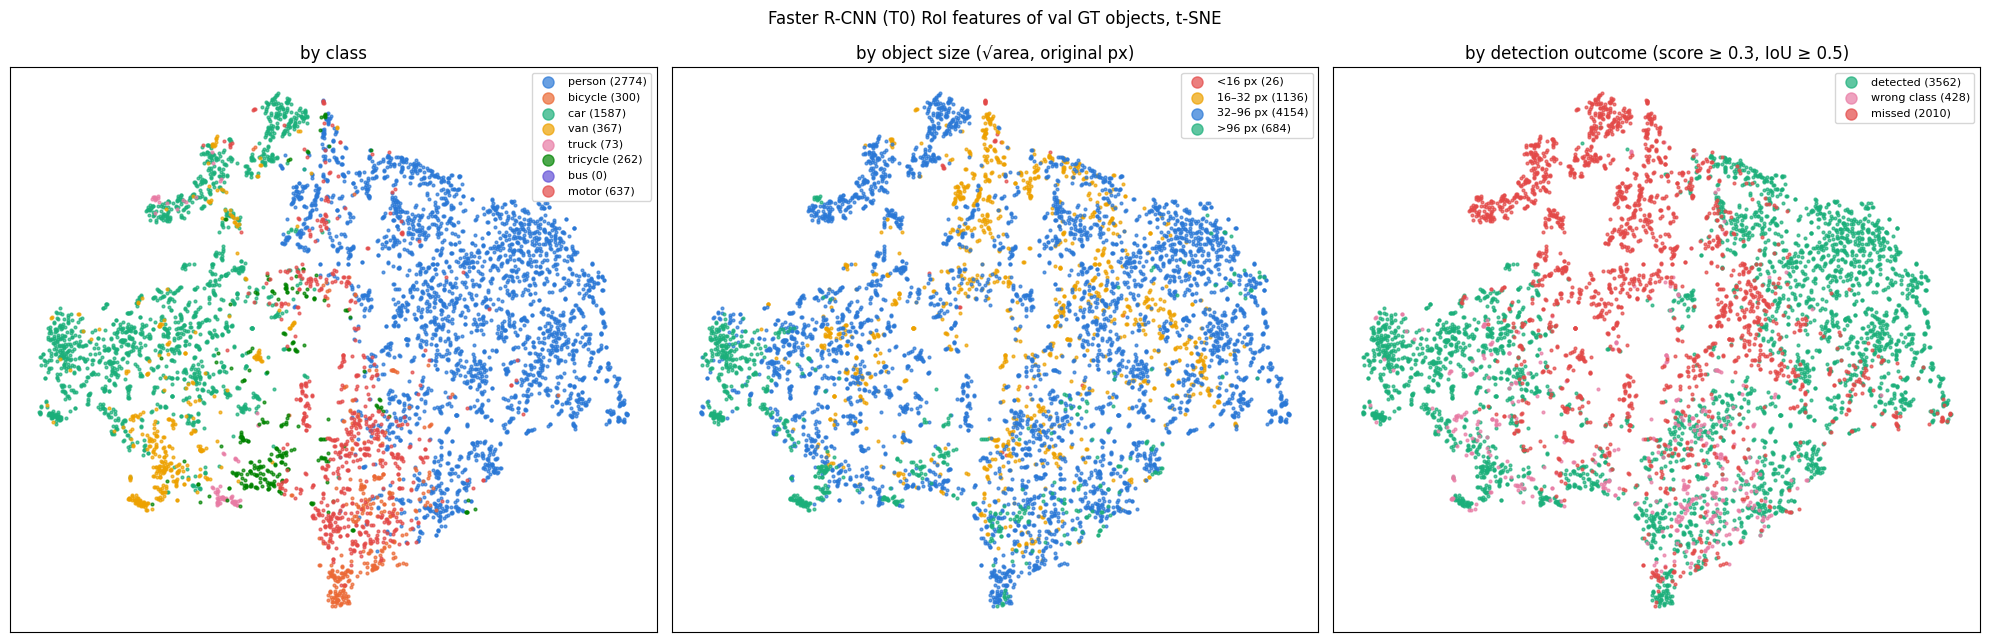

In [3]:
idx = np.random.default_rng(SEED).choice(len(X), size=min(MAX_POINTS, len(X)), replace=False)
Z = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(PCA(50, random_state=SEED).fit_transform(X[idx]))
d = df.iloc[idx].reset_index(drop=True); d["x"], d["y"] = Z[:, 0], Z[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for name, col in zip(NAMES, COLORS):
    s = d[d.cls == name]; axes[0].scatter(s.x, s.y, s=4, c=col, label=f"{name} ({len(s)})", alpha=0.7)
axes[0].set_title("by class"); axes[0].legend(markerscale=4, fontsize=8)
for lev, col in zip(["<16 px", "16–32 px", "32–96 px", ">96 px"], ["#e34948", "#eda100", "#2a78d6", "#1baf7a"]):
    s = d[d["size"] == lev]; axes[1].scatter(s.x, s.y, s=4, c=col, label=f"{lev} ({len(s)})", alpha=0.7)
axes[1].set_title("by object size (√area, original px)"); axes[1].legend(markerscale=4, fontsize=8)
for lev, col in [("detected", "#1baf7a"), ("wrong class", "#e87ba4"), ("missed", "#e34948")]:
    s = d[d.outcome == lev]; axes[2].scatter(s.x, s.y, s=4, c=col, label=f"{lev} ({len(s)})", alpha=0.7)
axes[2].set_title("by detection outcome (score ≥ 0.3, IoU ≥ 0.5)"); axes[2].legend(markerscale=4, fontsize=8)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle("Faster R-CNN (T0) RoI features of val GT objects, t-SNE")
plt.tight_layout(); plt.savefig(FIG / "roi_tsne_T0.png", dpi=130); plt.show()

## 4. Числа для інтерпретації
Частка пропусків за розміром і найчастіша плутанина класів серед об'єктів, які детектор «бачить», але називає не тим класом.

In [4]:
display(pd.crosstab(df["size"], df.outcome, normalize="index").round(3))
display(pd.crosstab(df.cls, df["size"]).T)
print("частка 'wrong class' по класах:", df[df.outcome == "wrong class"].cls.value_counts(normalize=True).round(3).to_dict())
d.to_csv(FIG / "roi_tsne_points.csv", index=False)

outcome,detected,missed,wrong class
size,,,
<16 px,0.078,0.902,0.020
16–32 px,0.484,0.456,0.060
32–96 px,0.584,0.342,0.073
>96 px,0.854,0.060,0.086


cls,bicycle,bus,car,motor,person,tricycle,truck,van
size,,,,,,,,
<16 px,0,0,0,20,31,0,0,0
16–32 px,9,0,339,557,1210,126,0,46
32–96 px,568,1,2223,659,4040,269,69,462
>96 px,76,1,620,66,213,119,76,176


частка 'wrong class' по класах: {'bicycle': 0.315, 'van': 0.225, 'motor': 0.193, 'tricycle': 0.122, 'person': 0.088, 'car': 0.05, 'truck': 0.005, 'bus': 0.002}
